### Mobilise D code (GSDB) coverting to Python

The GSDB(gait sequence detection) folder is gait detection using body acceleration recorded
with a trialxial acceleratometer worn/fixed on the lower back.

The GSD_LowBackAcc.m code is the file to extract gait events. There are several helper functions
within this code to help doing so. I'm here to translate all the .m file into Python language.
Once the functions are translated, I will use the csv/json/txt files extracted from the OMX GUI
interface to test out all the codes.

Note above: 04/09/2025

In [2]:
#!python -m pip install PyWavelets

import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt
import pywt
import pandas as pd
from scipy.interpolate import interp1d
from scipy.signal import hilbert, convolve

In [3]:
# resampInterp.m file
def resamp_interp(y, fs_initial, fs_final):
    recording_time = len(y)
    x = np.arange(1, recording_time + 1)
    xq = np.arange(1, recording_time + 1, fs_initial / fs_final)
    
    f = interp1d(x, y, kind='linear', bounds_error=False, fill_value="extrapolate")
    y_resamp = f(xq)
    return y_resamp


In [4]:
# groupfind.m file
def groupfind(L):
    L = np.asarray(L).flatten()
    temp = np.nonzero(L)[0]
    if len(temp) == 0:
        return np.empty((0, 2), dtype=int)
    
    idx = np.where(np.diff(temp) > 1)[0]
    starts = temp[np.insert(idx + 1, 0, 0)]
    ends = temp[np.append(idx, len(temp) - 1)]
    
    return np.column_stack((starts, ends))


In [5]:
# hilbert_envelop.m file

def hilbert_envelop(y, smooth_window=20, threshold_style=1, duration=20, gr=1):
    y = np.asarray(y).flatten()
    test = y
    analytic = hilbert(test)
    env = np.abs(analytic)

    # Smooth envelope
    env = convolve(env, np.ones(smooth_window) / smooth_window, mode='same')
    env -= np.mean(env)
    env /= np.max(env)

    # Threshold selection
    if threshold_style == 0:
        plt.figure()
        plt.plot(env)
        plt.title("Select a threshold")
        THR_SIG = float(input("Manual threshold value (0-1): "))
        plt.close()
    else:
        THR_SIG = 4 * np.mean(env)

    nois = np.mean(env) / 3
    threshold = np.mean(env)

    thres_buf = np.zeros(len(env) - duration)
    nois_buf = np.zeros(len(env) - duration)
    THR_buf = np.zeros(len(env))
    alarm = np.zeros(len(env))
    h = 1

    for i in range(len(env) - duration):
        window = env[i:i+duration]
        if np.all(window > THR_SIG):
            alarm[i] = np.max(env)
            threshold = 0.1 * np.mean(window)
            h += 1
        else:
            if np.mean(window) < THR_SIG:
                nois = np.mean(window)
            else:
                if len(nois_buf[:i]) > 0:
                    nois = np.mean(nois_buf[:i])

        thres_buf[i] = threshold
        nois_buf[i] = nois

        if h > 1:
            THR_SIG = nois + 0.50 * abs(threshold - nois)
        THR_buf[i] = THR_SIG

    if gr:
        fig, axs = plt.subplots(2, 1, sharex=True)
        axs[0].plot(test, label="Raw Signal")
        axs[0].plot(alarm * np.max(test), 'r', label="Detected Activity")
        axs[0].plot(THR_buf, '--g', label="Adaptive Threshold")
        axs[0].legend(loc="upper right")
        axs[0].set_title("Raw Signal and Detected Onsets of Activity")
        axs[0].grid(True)

        axs[1].plot(env, label="Smoothed Envelope")
        axs[1].plot(THR_buf, '--g', label="Adaptive Threshold")
        axs[1].plot(thres_buf, '--r', label="Activity Level")
        axs[1].plot(nois_buf, '--k', label="Noise Level")
        axs[1].legend(loc="upper right")
        axs[1].set_title("Smoothed Envelope (Hilbert Transform)")
        axs[1].grid(True)

        plt.tight_layout()
        plt.show()

    return alarm, env


In [6]:
def find_pulse_trains(x, fs=40):
    THD = 3.5 * fs
    walkflag = False
    w = []
    n = 0

    if len(x) > 2:
        for i in range(len(x) - 1):
            if x[i + 1] - x[i] < THD:
                if not walkflag:
                    walk = {'start': x[i], 'steps': 1}
                    walkflag = True
                    n += 1
                else:
                    walk['steps'] += 1
                    THD = 1.5 * fs + (x[i] - walk['start']) / walk['steps']
            else:
                if walkflag:
                    walk['end'] = x[i - 1]
                    w.append(walk)
                    walkflag = False
                    THD = 3.5 * fs

        if walkflag:
            if x[-1] - x[-2] < THD:
                walk['end'] = x[-1]
                walk['steps'] += 1
            else:
                walk['end'] = x[-2]
            w.append(walk)

    return w


In [7]:
def convert_w_to_set(w):
    s = np.zeros((len(w), 2), dtype=int)
    s[:, 0] = [entry['start'] for entry in w]
    s[:, 1] = [entry['end'] for entry in w]
    return s

In [8]:
def intersect(a, b):
    c = []
    ia, ib = 0, 0
    state = 3
    na, nb = a.shape[0], b.shape[0]

    while ia < na and ib < nb:
        if state == 1:
            if a[ia, 1] < b[ib, 0]:
                ia += 1
                state = 3
            elif a[ia, 1] < b[ib, 1]:
                c.append([b[ib, 0], a[ia, 1]])
                ia += 1
                state = 2
            else:
                c.append(list(b[ib]))
                ib += 1
        elif state == 2:
            if b[ib, 1] < a[ia, 0]:
                ib += 1
                state = 3
            elif b[ib, 1] < a[ia, 1]:
                c.append([a[ia, 0], b[ib, 1]])
                ib += 1
                state = 1
            else:
                c.append(list(a[ia]))
                ia += 1
        elif state == 3:
            if a[ia, 0] < b[ib, 0]:
                state = 1
            else:
                state = 2
    return np.array(c, dtype=int)

In [9]:
def pack_results(periods, peaks):
    w = []
    midswing = []

    for i in range(len(periods)):
        start = periods[i, 0]
        end = periods[i, 1]
        steps = [p for p in peaks if start <= p <= end]
        walk = {
            'start': start,
            'end': end,
            'steps': len(steps),
            'MidSwing': steps
        }

        if len(steps) > 2:
            step_time = np.mean(np.diff(steps))
            walk['start'] = int(np.floor(walk['start'] - 1.5 * step_time / 2))
            walk['end'] = int(np.floor(walk['end'] + 1.5 * step_time / 2))

        w.append(walk)
        midswing.extend(steps)

    # Merge overlapping periods
    i = 0
    while i < len(w) - 1:
        if w[i]['end'] >= w[i + 1]['start']:
            w[i]['end'] = w[i + 1]['end']
            w[i]['steps'] += w[i + 1]['steps']
            w[i]['MidSwing'].extend(w[i + 1]['MidSwing'])
            del w[i + 1]
        else:
            i += 1

    midswing = sorted(midswing)
    return w, midswing

In [10]:
def remove_drift_40hz(x):
    return signal.filtfilt([1, -1], [1, -0.9748], x)

def find_min_max(s, thr=None):
    d = np.diff(s)
    f = np.where(d[1:] * d[:-1] <= 0)[0] + 1
    mi = f[d[f] >= 0]
    ma = f[d[f] < 0]
    if thr is not None:
        ma = ma[s[ma] > thr]
        mi = mi[s[mi] < -thr]
    return mi, ma

def gsd_low_back_acc(imu_acc, fs, plot_results=False):
    acc = imu_acc
    algorithm_target_fs = 40
    accN = np.linalg.norm(acc, axis=1)

    # resample accN from fs to 40 Hz
    accN40 = resamp_interp(accN, fs, algorithm_target_fs)

    accN_filt1 = signal.savgol_filter(accN40, 21, 7)
    accN_filt2 = signal.filtfilt([1, -1], [1, -0.9748], accN_filt1)
    accN_filt3 = pywt.cwt(accN_filt2, 10, 'gaus2', sampling_period=1/40)[0][0]
    accN_filt4 = signal.savgol_filter(accN_filt3, 11, 5)
    accN_filt5 = pywt.cwt(accN_filt4, 10, 'gaus2', sampling_period=1/40)[0][0]

    # Smoothing stages
    accN_filt6 = signal.convolve(accN_filt5, signal.windows.gaussian(10, std=2), mode='same') / 10
    accN_filt7 = signal.convolve(accN_filt6, signal.windows.gaussian(10, std=2), mode='same') / 10
    accN_filt8 = signal.convolve(accN_filt7, signal.windows.gaussian(15, std=2), mode='same') / 15
    accN_filt9 = signal.convolve(accN_filt8, signal.windows.gaussian(10, std=2), mode='same') / 10

    sig_det_actv = accN_filt9

    alarm, _ = hilbert_envelop(sig_det_actv, smooth_window=20, threshold_style=1, duration=algorithm_target_fs, gr=0)
    walkLowBack = []
    if np.any(alarm):
        idx = groupfind(alarm > 0)
        for j in range(idx.shape[0]):
            if idx[j, 1] - idx[j, 0] <= 3 * algorithm_target_fs:
                alarm[idx[j, 0]:idx[j, 1]] = 0
            else:
                walkLowBack.extend(sig_det_actv[idx[j, 0]:idx[j, 1]])
        walkLowBack = np.array(walkLowBack)
        pksp, _ = signal.find_peaks(walkLowBack)
        pksn, _ = signal.find_peaks(-walkLowBack)
        pks = np.concatenate((walkLowBack[pksp], -walkLowBack[pksn]))
        th = np.percentile(pks[pks > 0], 5)
        f = sig_det_actv
    else:
        th = 0.15
        f = accN_filt4

    min_peaks, max_peaks = find_min_max(f, th)
    
    t1 = find_pulse_trains(max_peaks)
    t1 = [t for t in t1 if t['steps'] >= 4]
    t2 = find_pulse_trains(min_peaks)
    t2 = [t for t in t2 if t['steps'] >= 4]
    t_final = intersect(convert_w_to_set(t1), convert_w_to_set(t2))

    if t_final.size == 0:
        w = []
        midswing = []
    else:
        w, midswing = pack_results(t_final, max_peaks)
        if w:
            w[0]['start'] = max(0, w[0]['start'])
            w[-1]['end'] = min(len(sig_det_actv) - 1, w[-1]['end'])

    w_new = [walk for walk in w if walk['steps'] >= 5]

    walk_label = np.zeros(len(sig_det_actv), dtype=int)
    for walk in w_new:
        walk_label[walk['start']:walk['end']] = 1

    ind_no_wk = groupfind(walk_label == 0)
    for j in range(ind_no_wk.shape[0]):
        if ind_no_wk[j, 1] - ind_no_wk[j, 0] <= 3 * algorithm_target_fs:
            walk_label[ind_no_wk[j, 0]:ind_no_wk[j, 1]] = 1
    
    # This section will process and return GSD_Output
    GSD_Output = []
    if np.any(walk_label == 1):
        ind_wk = groupfind(walk_label == 1)
        for j in range(ind_wk.shape[0]):
            GSD_Output.append({
                'Start': ind_wk[j, 0] / algorithm_target_fs,
                'End': ind_wk[j, 1] / algorithm_target_fs,
                'fs': fs
            })
    else:
        print("No gait sequence(s) detected")

    if plot_results:
        plt.plot(sig_det_actv)
        plt.plot(walk_label, 'r', linewidth=2)
        plt.legend(['filtered accNorm', 'Walking'])
        plt.xlabel('samples (100Hz)')
        plt.show()

    return GSD_Output

In [11]:
import os

#TODO: get proper file type
# notebook_dir = os.path.dirname(os.path.abspath("__file__"))
# data_path = os.path.normpath(os.path.join(notebook_dir, '..', 'df222222.csv'))
# df = pd.read_csv(data_path)

##OLD CODE
data_path = "C:/Users/ahala/OneDrive/Desktop/SoangraResearch/McRobertsAnalysis/Data/CSV_Files_Raw/TestData_directConversion.csv"
df = pd.read_csv(data_path)

In [12]:
# Extract IMU acceleration (assume Channel_1 to Channel_3 are X, Y, Z)
imu_acc = df[['Ax', 'Ay', 'Az']].values
fs = 100  

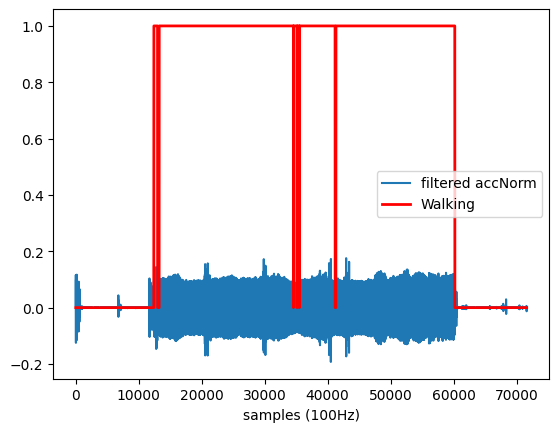

[{'Start': np.float64(309.75), 'End': np.float64(324.625), 'fs': 100},
 {'Start': np.float64(330.9), 'End': np.float64(864.125), 'fs': 100},
 {'Start': np.float64(864.175), 'End': np.float64(878.7), 'fs': 100},
 {'Start': np.float64(878.75), 'End': np.float64(887.7), 'fs': 100},
 {'Start': np.float64(887.75), 'End': np.float64(1029.45), 'fs': 100},
 {'Start': np.float64(1032.65), 'End': np.float64(1504.7), 'fs': 100}]

In [13]:
# plot_results = True
gsd_low_back_acc(imu_acc, fs, True)

# GSDA Code converted to Python

In [13]:
# GetFields.m file
def get_fields(data, curr_structure='data', rfields=None):
    if rfields is None:
        rfields = []

    current = eval(curr_structure)

    for key in current:
        value = current[key]
        new_path = f"{curr_structure}.{key}"
        if isinstance(value, dict):
            rfields = get_fields(data, new_path, rfields)
        else:
            rfields.append(new_path)
    return rfields

In [14]:
def gsd_iluz(imu, plot_results=False):
    algorithm_target_fs = 100
    algorithm_output_fs = 100

    WinS = algorithm_target_fs * 3  # window size
    OL = WinS // 2                  # overlap
    activity_thresh = 0.01

    try:
        imu_preprocessed = preprocessing_standardized(imu, algorithm_target_fs)

        gait_sequences_bool = WBDet_Sine(
            imu_preprocessed,
            algorithm_target_fs,
            WinS,
            OL,
            activity_thresh,
            plot_results
        )

        GSD = save_gsd_result(gait_sequences_bool, algorithm_output_fs)
    except Exception as e:
        print(f"Warning: GSD algorithm failed: {e}")
        GSD = []

    return GSD


In [15]:
# preprocessing_standardized.m

from scipy.signal import resample

def preprocessing_standardized(IMU, algorithm_target_fs):
    acc = IMU['LowerBack']['Acc']
    gyr = IMU['LowerBack']['Gyr']
    fs_acc = IMU['LowerBack']['Fs']['Acc']

    if algorithm_target_fs != fs_acc:
        acc_resampled = resample(acc, int(len(acc) * algorithm_target_fs / fs_acc))
        gyr_resampled = resample(gyr, int(len(gyr) * algorithm_target_fs / fs_acc))
        imu_preprocessed = np.hstack([acc_resampled, gyr_resampled])
    else:
        imu_preprocessed = np.hstack([acc, gyr])

    return imu_preprocessed


In [16]:
# save_gsd_result.m file

def save_gsd_result(walking_bool_vector, algorithm_output_fs):
    if np.all(walking_bool_vector == 0):
        return [{
            'GaitSequence_Start': float('nan'),
            'GaitSequence_End': float('nan'),
            'GSD_fs': algorithm_output_fs
        }]

    walking_bool_vector = walking_bool_vector.flatten()
    edges = np.diff(walking_bool_vector.astype(int))
    starts = list(np.where(edges == 1)[0] + 1)
    ends = list(np.where(edges == -1)[0] + 1)

    if walking_bool_vector[0] == 1:
        starts.insert(0, 0)
    if walking_bool_vector[-1] == 1:
        ends.append(len(walking_bool_vector))

    gait_sequences = []
    for s, e in zip(starts, ends):
        gait_sequences.append({
            'GaitSequence_Start': s / algorithm_output_fs,
            'GaitSequence_End': e / algorithm_output_fs,
            'GSD_fs': algorithm_output_fs
        })

    return gait_sequences


In [17]:
# Find_Peaks.m file

import numpy as np
import matplotlib.pyplot as plt

def find_peaks(vec, th, do_plot=0):
    vec = np.asarray(vec)
    vec_s = vec - np.mean(vec)  # normalize
    A = np.append(0, vec_s) * np.append(vec_s, 0)
    Z = np.where(A < 0)[0]

    if len(Z) == 0:
        return []

    min_dist = np.where(np.diff(np.append(0, Z)) > th)[0]
    bumps = Z[min_dist]
    Bp = bumps[::2]

    if len(Bp) < 2:
        return []

    diff_bp = np.diff(np.append(0, Bp))
    try:
        mean_diff = np.mean(diff_bp[1:-1])
        miss_p = np.where(diff_bp[1:-1] > 1.2 * mean_diff)[0] + 1
    except:
        miss_p = []

    if len(miss_p) != 0:
        Bn = np.sort(np.append(Bp, Bp[miss_p - 1] + ((Bp[miss_p] - Bp[miss_p - 1]) // 2)))
    else:
        Bn = Bp

    L_Bp = len(Bn)

    if L_Bp == 0:
        return []

    if len(vec_s) > Bn[-1] + 2:
        Bn = np.append(Bn, len(vec_s))
    else:
        L_Bp -= 1

    P_L = []
    for z in range(L_Bp):
        segment = vec_s[Bn[z] + 1 : Bn[z + 1] - 1]
        if len(segment) == 0:
            continue
        peak_idx = np.argmax(segment)
        P_L.append(Bn[z] + 1 + peak_idx)

    if do_plot:
        plt.figure()
        plt.plot(vec_s, label='Signal')
        plt.stem(P_L, vec_s[P_L], linefmt='r-', markerfmt='ro', label='Peaks')
        plt.stem(Bn, vec_s[Bn], linefmt='g-', markerfmt='go', label='Zero-crossings')
        plt.legend()
        plt.show()

    return P_L


In [18]:
# WBDet_Sine.m file

from scipy.signal import firwin, lfilter
from scipy.signal import convolve as conv
from numpy.lib.stride_tricks import sliding_window_view

def WBDet_Sine(imu, sample_rate, win_size, overlap, activity_thresh, plot_results=False):
    acc = imu[:, :3]
    v_acc = acc[:, 0]
    ap_acc = acc[:, 2]

    # Bandpass filter: 0.5–3 Hz
    b = firwin(201, [0.5, 3], pass_zero=False, fs=sample_rate)
    v_filt = lfilter(b, 1.0, v_acc)
    ap_filt = lfilter(b, 1.0, ap_acc)

    # Skip the first second of data
    v_filt = v_filt[int(sample_rate):]
    ap_filt = ap_filt[int(sample_rate):]

    # Convolve with sine template
    template = np.sin(2 * np.pi * np.linspace(0, 0.5, int(sample_rate / 2)))
    v_conv = conv(v_acc - 1, template, mode='full')[len(template):]
    ap_conv = conv(ap_acc, template, mode='full')[len(template):]

    # Buffer and activity thresholding
    v_buf = sliding_window_view(v_conv, window_shape=win_size)[::(win_size - overlap)]
    stds = np.std(v_buf, axis=1)
    active_windows = np.where(stds > activity_thresh)[0]

    gait_bool = np.zeros(len(v_acc), dtype=int)
    for win_idx in active_windows:
        start = win_idx * (win_size - overlap)
        end = start + win_size
        if end > len(gait_bool):
            continue
        gait_bool[start:end] = 1  # Placeholder logic

    if plot_results:
        import matplotlib.pyplot as plt
        plt.plot(v_acc, label='Vertical Acc')
        plt.plot(gait_bool * np.max(v_acc), label='Detected Gait')
        plt.legend()
        plt.show()

    return gait_bool


In [19]:
# driver.m file
import os
import json
from scipy.io import loadmat, savemat

def driver(indir, outdir):
    try:
        # Load the .mat file
        mat_data = loadmat(os.path.join(indir, 'data.mat'), struct_as_record=False, squeeze_me=True)
        data = mat_data['data']

        # Get all field paths ending in 'LowerBack.Acc'
        all_fields = get_fields(data, 'data', [])
        acc_fields = [f for f in all_fields if 'LowerBack.Acc' in f and 'SU_INDIP' not in f]

        GSD_Output = {}
        for path in acc_fields:
            field_parts = path.split('.')[1:-2]  # remove 'data.' prefix and '.Acc'
            imu_struct = data
            for part in field_parts:
                imu_struct = getattr(imu_struct, part) if hasattr(imu_struct, part) else imu_struct[part]

            gsd_result = GSD_Iluz(imu_struct)  # your gait detection logic here
            gsd_path = field_parts + ['GSD']

            d = GSD_Output
            for key in gsd_path[:-1]:
                d = d.setdefault(key, {})
            d[gsd_path[-1]] = gsd_result

        # Save JSON
        os.makedirs(outdir, exist_ok=True)
        with open(os.path.join(outdir, 'GSDA_Output.json'), 'w') as f:
            json.dump({'GSDA_Output': GSD_Output}, f, indent=2)

        # Save MAT
        savemat(os.path.join(outdir, 'GSDA_Output.mat'), {'GSD_Output': GSD_Output})

        return 'ok'

    except Exception as e:
        print(f"Error during processing: {e}")
        return 'error'


In [20]:
import pandas as pd
#Same path as above
#data_path = "/Users/minhaohuang/Desktop/Grad Assistant/extracted_data.csv" #TODO: use local file path
data_path = "C:/Users/ahala/OneDrive/Desktop/SoangraResearch/McRobertsAnalysis/Data/CSV_Files_Raw/TestData.csv"
df = pd.read_csv(data_path)

In [21]:
acc = df[['Ax','Ay','Az']].values
gyr = df[['Gx','Gy','Gz']].values
fs = 100

imu = {
    'LowerBack': {
        'Acc': acc,
        'Gyr': gyr,
        'Fs': {
            'Acc': fs,
            'Gyr': fs
        }
    }
}

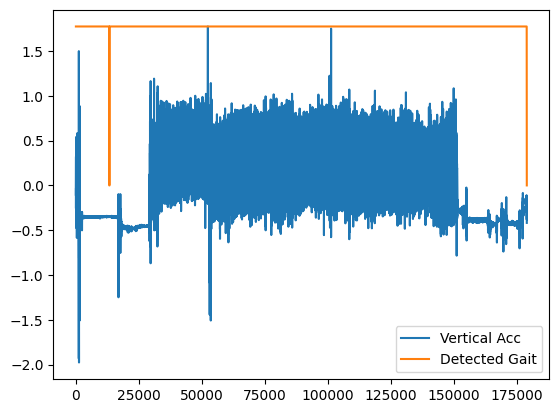

   GaitSequence_Start  GaitSequence_End  GSD_fs
0                 0.0             132.0     100
1               133.5            1789.5     100


In [22]:
gsd_output = gsd_iluz(imu, plot_results=True)

df_output = pd.DataFrame(gsd_output)
print(df_output)

# ICDA Code converted to Python

In [23]:
from scipy.signal import filtfilt
from scipy.interpolate import interp1d
from scipy.signal import convolve
from scipy.io import loadmat
import pywt

In [24]:
def remove_drift_40hz(x):
    return filtfilt([1, -1], [1, -0.9748], x)

def max_peaks_between_zc(signal):
    """ Emulates MaxPeaksBetweenZC by detecting peaks between zero crossings. """
    zero_crossings = np.where(np.diff(np.signbit(signal)))[0]
    peaks = []
    peak_indices = []
    
    for i in range(len(zero_crossings) - 1):
        seg = signal[zero_crossings[i]:zero_crossings[i+1]]
        if len(seg) == 0:
            continue
        local_peak_idx = np.argmax(np.abs(seg))
        true_idx = zero_crossings[i] + local_peak_idx
        peaks.append(signal[true_idx])
        peak_indices.append(true_idx)
    
    return np.array(peaks), np.array(peak_indices)

def sd_algo_amc(accV, fs):
    algorithm_target_fs = 40

    # resample using same method from earlier translation
    accV40 = resamp_interp(accV, fs, algorithm_target_fs)

    Num = loadmat("C:/Users/ahala/OneDrive/Desktop/SoangraResearch/McRobertsAnalysis/Mobilise-D-TVS-Recommended-Algorithms-master/ICDA/Library/FIR-2-3Hz-40.mat")['Num'].flatten()

    len_padd = 10000 * len(Num)
    accV40_zp = np.pad(accV40, pad_width=len_padd, mode='wrap')
    accV40_lpf = filtfilt(Num, [1], remove_drift_40hz(accV40_zp))
    accV40_lpf_rmzp = accV40_lpf[len_padd:-len_padd]

    accVLPInt = np.cumsum(accV40_lpf_rmzp) / algorithm_target_fs
    accVLPIntCwt, _ = pywt.cwt(accVLPInt, 9, 'gaus2', sampling_period=1 / algorithm_target_fs)
    accVLPIntCwt = accVLPIntCwt[0] - np.mean(accVLPIntCwt[0])

    pks1, ipks1 = max_peaks_between_zc(accVLPIntCwt)
    IC = ipks1[pks1 < 0] / algorithm_target_fs  # Initial Contacts

    accVLPIntCwt2, _ = pywt.cwt(accVLPIntCwt, 9, 'gaus2', sampling_period=1 / algorithm_target_fs)
    accVLPIntCwt2 = accVLPIntCwt2[0] - np.mean(accVLPIntCwt2[0])

    pks2, ipks2 = max_peaks_between_zc(accVLPIntCwt2)
    FC = ipks2[pks2 > 0] / algorithm_target_fs  # Final Contacts

    return IC, FC


In [28]:
def step_detection(imu_acc, GS, fs, plot_results=False):
    acc_v = imu_acc[:, 0]  # vertical acceleration

    if isinstance(GS, list) and len(GS) > 0 and 'Start' in GS[0] and 'End' in GS[0]:
        SD_Output = []

        for j in range(len(GS)):
            start = round(fs * GS[j]['Start'])
            stop = round(fs * GS[j]['End'])
            acc_v_gs = acc_v[start:stop]

            try:
                IC_rel, _ = sd_algo_amc(acc_v_gs, fs)  # assumes this function is defined
                IC = GS[j]['Start'] + IC_rel
                GS[j]['IC'] = IC.tolist()
            except Exception as e:
                print(f"Warning: Step detection failed for segment {j}: {e}")
                GS[j]['IC'] = []

        SD_Output = GS
    else:
        return []

    if plot_results:
        Num = loadmat("C:/Users/ahala/OneDrive/Desktop/SoangraResearch/McRobertsAnalysis/Mobilise-D-TVS-Recommended-Algorithms-master/ICDA/Library/FIR-2-3Hz-40.mat")['Num'].flatten()  

        fs_algo = 40
        IC_all_sig = np.concatenate([np.array(g['IC']) for g in GS if 'IC' in g and len(g['IC']) > 0])
        ICs = np.round(IC_all_sig * fs).astype(int)

        acc_v_40 = resamp_interp(acc_v, fs, fs_algo)
        acc_v_lpf = filtfilt(Num, [1], remove_drift_40hz(acc_v_40))
        acc_v_lpf_int = np.cumsum(acc_v_lpf) / fs_algo
        acc_v_lpf_cwt, _ = pywt.cwt(acc_v_lpf_int, 9, 'gaus2', sampling_period=1 / fs_algo)
        acc_v_lpf_cwt = acc_v_lpf_cwt[0] - np.mean(acc_v_lpf_cwt[0])
        acc_v_processed = resamp_interp(acc_v_lpf_cwt, fs_algo, fs)

        plt.figure()
        plt.plot(np.arange(len(acc_v_processed)), acc_v_processed, 'b', label='accV (processed)')
        plt.plot(ICs, acc_v_processed[ICs], 'ro', label='Initial Contacts (IC)')
        plt.legend()
        plt.title("Step Detection")
        plt.xlabel("Samples")
        plt.show()

    return SD_Output

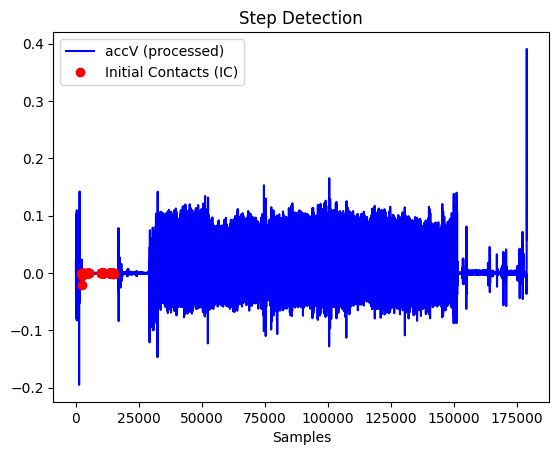

In [29]:
gsd_output = [
     {'Start': 20.15, 'End': 31.70, 'fs': 100},
     {'Start': 42.525, 'End': 52.9, 'fs': 100},
     {'Start': 97.85, 'End': 112.075, 'fs': 100},
     {'Start': 131.6, 'End': 139.75, 'fs': 100},
     {'Start': 139.8, 'End': 151.25, 'fs': 100}
]

sd_output = step_detection(imu_acc, gsd_output, fs, True)

In [36]:
sd_output

[]